# Phase 2.2 - Feature Selection

## 1. Introduction and requirements

Compare Mutual Information, Logistic Regression RFE and Random Forest importance.
This covers 2.2(A): at least three techniques and comparison; (B): rankings;
and (C): explanations and decisions. The assignment and previous phases were
reviewed. Seminar notebooks are unavailable locally, so no direct comparison
with seminar examples is claimed.

Use the Phase 2.1 Standard training CSV and the project `.venv`. Do not re-split,
repeat preprocessing or use test data. Rankings are exploratory, not performance
scores. Keep both the group-voting proposal and its version without depot.
Neither is a validated optimum.

Contributions: Dmytro Petrenko [actual %]; Oleh Serdiukov [actual %].


In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning

DATA = Path("data") if Path("data").is_dir() else Path("../data")
TRAIN_CSV = DATA / "processed" / "phase2_train_standard.csv"
if not TRAIN_CSV.is_file():
    raise FileNotFoundError("Run Phase 2.1 first to generate its Standard training export.")
SEED = 42
TOP_K = 20


## 2. Data loading and validation

Reuse all 10,512 training rows, 256 predictors and original Failure labels.
Check numeric types, finite values, constants and duplicate columns; keep all rows.
The CSV has no verified device IDs, so do not reconstruct groups from its order
or report cross-validation here. Full-training imputation/scaling would need to
be fitted again inside validation folds. Phase 2.3 restores a verified group map.


In [2]:
training = pd.read_csv(TRAIN_CSV)
assert training.shape == (10512, 257), "Review the Phase 2.1 export if its schema changed."
assert training.columns.is_unique
assert "Failure" in training
X = training.drop(columns="Failure").copy()
y = training["Failure"].copy()
assert y.isin([0, 1]).all() and set(y) == {0, 1}
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes)
assert np.isfinite(X.to_numpy()).all()
assert not {"Failure", "unitId", "unit_key", "serialNumber", "ts_cycle"} & set(X.columns)
display(y.value_counts().sort_index().rename("rows").to_frame()
        .assign(percent=lambda d: 100*d["rows"]/len(y)).round(2))
print("Predictors:", X.shape[1], "Rows:", len(X))
print("Repeated complete exported rows:", training.duplicated().sum(), "(retained)")
print("Constant columns:", X.columns[X.nunique(dropna=False).le(1)].to_list())
assert not any(np.array_equal(X[c].to_numpy(), y.to_numpy()) or
               np.array_equal(X[c].to_numpy(), 1-y.to_numpy()) for c in X), "Review a perfect target proxy."


,rows,percent
Failure,,
0,9234,87.84
1,1278,12.16


Predictors: 256 Rows: 10512
Repeated complete exported rows: 0 (retained)


Constant columns: []


### Constant and duplicate columns

Use one copy of each exactly repeated column in the selection view; do not edit
the source CSV. Prefer unit_metadata_missing over repeated category-missing dummies
and temperatureOil_missing over its repeated invalid flag. Record these aliases.

Equality holds in this training data, not necessarily in future data. Recheck it
when refitting preprocessing. Do not merge merely correlated features such as
filterDp and vibrationRms missingness.


In [3]:
constant_features = X.columns[X.nunique(dropna=False).le(1)].to_list()
priority = ["unit_metadata_missing", "temperatureOil_missing"]
scan_order = [c for c in priority if c in X and c not in constant_features]
scan_order += [c for c in X if c not in scan_order and c not in constant_features]
canonical = []
aliases = {}
for column in scan_order:
    duplicate = None
    for kept in canonical:
        if X[column].equals(X[kept]):
            duplicate = kept
            break
    if duplicate is None:
        canonical.append(column)
    else:
        aliases[column] = duplicate
candidate_names = [c for c in X if c in canonical]
X_candidates = X[candidate_names].copy()
assert not X_candidates.T.duplicated().any()
print("Selection view:", X_candidates.shape)
display(pd.DataFrame([{"duplicate_column": a, "canonical_column": b} for a,b in aliases.items()]))

Selection view: (10512, 250)


,duplicate_column,canonical_column
0,codeLine_missing,unit_metadata_missing
1,class_duty_missing,unit_metadata_missing
2,id_depot_missing,unit_metadata_missing
3,owner_operator_missing,unit_metadata_missing
4,installRegion_missing,unit_metadata_missing
5,temperatureOil_invalid,temperatureOil_missing


In [4]:
numeric_attributes = ["motorCurrent", "filterDp", "temperatureOil", "pressure_reservoir",
    "vibrationRms", "flowmeter", "tempBearing", "discharge_dewpoint", "commission_year", "serviceHours"]
category_attributes = ["codeLine", "class_duty", "id_depot", "owner_operator", "installRegion"]

def original_group(column):
    if column == "unit_metadata_missing":
        return "metadata_availability"
    if column in numeric_attributes:
        return column
    if column.endswith("_missing") and column[:-8] in numeric_attributes:
        return column[:-8]
    if column == "temperatureOil_invalid":
        return "temperatureOil"
    for attribute in category_attributes:
        if column.startswith(attribute + "_"):
            return attribute
    raise ValueError(f"Unrecognised predictor group: {column}")

feature_groups = pd.Series({c: original_group(c) for c in X_candidates}, name="original_group")
display(feature_groups.value_counts().rename("candidate_columns").to_frame())
flag_names = [c for c in X_candidates if c.endswith("_missing")]
flag_rates = X_candidates[flag_names].groupby(y).mean().T.mul(100)
flag_rates.columns = [f"Failure_{label}_percent" for label in flag_rates.columns]
print("Training flag prevalence by Failure (association, not evidence of timing):")
display(flag_rates.round(2))

# Inspect strong correlations among numeric attributes and flags, not all dummy pairs.
audit_names = list(dict.fromkeys([c for c in numeric_attributes if c in X_candidates] + flag_names))
corr = X_candidates[audit_names].corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Strongest absolute Spearman correlations among numbers and flags:")
display(upper.sort_values(ascending=False).head(8).rename("abs_spearman").to_frame().round(3))

,candidate_columns
original_group,
id_depot,120
installRegion,59
owner_operator,40
class_duty,10
codeLine,6
filterDp,2
temperatureOil,2
vibrationRms,2
serviceHours,2


Training flag prevalence by Failure (association, not evidence of timing):


,Failure_0_percent,Failure_1_percent
filterDp_missing,2.11,18.86
vibrationRms_missing,1.91,19.09
temperatureOil_missing,0.26,0.55
serviceHours_missing,5.64,6.18
unit_metadata_missing,0.97,0.86


Strongest absolute Spearman correlations among numbers and flags:


,,abs_spearman
commission_year,serviceHours,0.963
serviceHours_missing,unit_metadata_missing,0.400
filterDp_missing,vibrationRms_missing,0.084
commission_year,vibrationRms_missing,0.051
serviceHours,vibrationRms_missing,0.048
tempBearing,filterDp_missing,0.037
pressure_reservoir,vibrationRms_missing,0.034
commission_year,filterDp_missing,0.029


## 3. Mutual Information

MI measures each feature's association with Failure separately, in nats. It gives
no direction or causal effect and can miss interactions. Mark binary/one-hot
columns and commission_year as discrete; integer-code the standardized year only
for MI. Treat the other nine numeric attributes as continuous, with three
neighbours and seed 42.

All 250 candidates have positive estimates in this run. Small positive values
can reflect sampling noise and repeated device readings, not useful prediction.
Compare ranks; MI > 0 is not a significance test.


In [5]:
binary_mask = pd.Series({c: X_candidates[c].isin([0, 1]).all() for c in X_candidates})
discrete_mask = binary_mask.copy()
discrete_mask.loc["commission_year"] = True
X_mi = X_candidates.copy()
X_mi["commission_year"] = pd.factorize(X_mi["commission_year"], sort=True)[0]
mi_scores = mutual_info_classif(X_mi, y, discrete_features=discrete_mask.to_numpy(),
                              n_neighbors=3, random_state=SEED)
mi_table = pd.DataFrame({"feature": X_candidates.columns, "MI_nats": mi_scores})
mi_table["MI_rank"] = mi_table["MI_nats"].rank(ascending=False, method="average")
mi_table = mi_table.sort_values(["MI_nats", "feature"], ascending=[False, True]).reset_index(drop=True)
assert np.isfinite(mi_scores).all() and (mi_scores >= 0).all()
print("Discrete predictors:", discrete_mask.sum(), "; continuous:", (~discrete_mask).sum())
display(mi_table.head(TOP_K))
display(Markdown("**MI result:** highest scores: " + ", ".join(
    f"{r.feature} ({r.MI_nats:.4f})" for r in mi_table.head(5).itertuples()) +
    f". {int((mi_table.MI_nats > 0).sum())} candidates have positive estimates. "
    "The complete ranking is retained for the combined CSV; these scores are not validated performance."))


Discrete predictors: 241 ; continuous: 9


,feature,MI_nats,MI_rank
0,vibrationRms,0.032167,1.0
1,filterDp,0.032091,2.0
2,vibrationRms_missing,0.025638,3.0
3,filterDp_missing,0.023834,4.0
4,serviceHours,0.010941,5.0
5,commission_year,0.010278,6.0
6,motorCurrent,0.007919,7.0
7,pressure_reservoir,0.007704,8.0
8,tempBearing,0.007448,9.0
9,discharge_dewpoint,0.005238,10.0


**MI result:** highest scores: vibrationRms (0.0322), filterDp (0.0321), vibrationRms_missing (0.0256), filterDp_missing (0.0238), serviceHours (0.0109). 250 candidates have positive estimates. The complete ranking is retained for the combined CSV; these scores are not validated performance.

## 4. Recursive Feature Elimination (RFE)

RFE repeatedly removes predictors with small Logistic Regression coefficients.
L2 regularization handles correlated inputs; balanced class weights give Failure
rows more weight. This measures conditional linear relationships, unlike MI.

Select 20 columns as a manageable exploratory shortlist, not a tuned optimum.
Remove 10% per step to limit runtime. For RFE only, standardize every candidate
on train so coefficient magnitudes have comparable units; the source CSV is
unchanged. Selected columns have rank 1 and eliminated batches share ranks.
Order the selected columns by final coefficient magnitude for display. Correlated
features and dummy coding can make the chosen representatives unstable.


In [6]:
rfe_scaler = StandardScaler()
X_rfe = rfe_scaler.fit_transform(X_candidates)
rfe = RFE(
    estimator=LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                 class_weight="balanced", random_state=SEED),
    n_features_to_select=TOP_K, step=0.10,
)
with warnings.catch_warnings(record=True) as rfe_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    rfe.fit(X_rfe, y)
assert not any(issubclass(w.category, ConvergenceWarning) for w in rfe_warnings), "Check Logistic Regression convergence."
assert rfe.support_.sum() == TOP_K
rfe_table = pd.DataFrame({"feature": X_candidates.columns,
    "RFE_rank": rfe.ranking_, "RFE_selected": rfe.support_})
rfe_table = rfe_table.sort_values(["RFE_rank", "feature"]).reset_index(drop=True)
selected_rfe = X_candidates.columns[rfe.support_].to_list()
rfe_selected_table = pd.DataFrame({"feature": selected_rfe,
    "coefficient": rfe.estimator_.coef_[0]})
rfe_selected_table["abs_coefficient"] = rfe_selected_table.coefficient.abs()
rfe_selected_table = rfe_selected_table.sort_values(["abs_coefficient", "feature"], ascending=[False, True])
print("RFE ranking (all selected columns have rank 1):")
display(rfe_table.head(TOP_K))
print("Selected columns ordered by final standardized coefficient magnitude:")
display(rfe_selected_table)
display(Markdown(f"**RFE result:** selected {len(selected_rfe)} of {X_candidates.shape[1]} candidates. "
    f"The final fit converged in {int(rfe.estimator_.n_iter_.max())} iterations. "
    "Its largest selected coefficient magnitudes belong to " +
    ", ".join(rfe_selected_table.head(5).feature) +
    ". Signs describe this fitted linear model, not causality or independent significance."))


RFE ranking (all selected columns have rank 1):


,feature,RFE_rank,RFE_selected
0,class_duty_1,1,True
1,class_duty_3,1,True
2,class_duty_H,1,True
3,class_duty_L,1,True
4,class_duty_heavy,1,True
5,class_duty_light,1,True
6,commission_year,1,True
7,discharge_dewpoint,1,True
8,filterDp,1,True
9,filterDp_missing,1,True


Selected columns ordered by final standardized coefficient magnitude:


,feature,coefficient,abs_coefficient
16,id_depot_98.0,-0.545015,0.545015
19,vibrationRms_missing,0.499986,0.499986
18,filterDp_missing,0.498586,0.498586
0,motorCurrent,0.402123,0.402123
15,id_depot_81.0,-0.392711,0.392711
6,commission_year,-0.346462,0.346462
1,filterDp,0.303843,0.303843
4,tempBearing,0.296665,0.296665
12,class_duty_light,0.259702,0.259702
7,class_duty_1,0.248556,0.248556


**RFE result:** selected 20 of 250 candidates. The final fit converged in 17 iterations. Its largest selected coefficient magnitudes belong to id_depot_98.0, vibrationRms_missing, filterDp_missing, motorCurrent, id_depot_81.0. Signs describe this fitted linear model, not causality or independent significance.

## 5. Random Forest Feature Importance

Use 300 trees, minimum leaf size 5, seed 42 and balanced bootstrap class weights.
These fixed settings are not tuned on test data. Tree importance (MDI) sums
contributions to splits, including nonlinear relationships and interactions;
the importances sum to 1.

Continuous features offer more split points, and groups with many dummies have
more opportunities to contribute. Correlated predictors may share importance.
Training importance is not held-out performance; repeated device metadata can
also be memorised.


In [7]:
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
    class_weight="balanced_subsample", max_features="sqrt", random_state=SEED, n_jobs=2)
forest.fit(X_candidates, y)
rf_table = pd.DataFrame({"feature": X_candidates.columns, "RF_importance": forest.feature_importances_})
rf_table["RF_rank"] = rf_table.RF_importance.rank(ascending=False, method="average")
rf_table = rf_table.sort_values(["RF_importance", "feature"], ascending=[False, True]).reset_index(drop=True)
assert np.isfinite(forest.feature_importances_).all()
assert np.isclose(rf_table.RF_importance.sum(), 1)
display(rf_table.head(TOP_K))
display(Markdown("**Random Forest result:** the leading split-importance features are " +
    ", ".join(f"{r.feature} ({r.RF_importance:.4f})" for r in rf_table.head(5).itertuples()) +
    ". These are fitted training importances, not estimates of generalisation accuracy."))

,feature,RF_importance,RF_rank
0,filterDp,0.091888,1.0
1,filterDp_missing,0.071841,2.0
2,vibrationRms_missing,0.071711,3.0
3,tempBearing,0.070149,4.0
4,serviceHours,0.068918,5.0
5,vibrationRms,0.065555,6.0
6,motorCurrent,0.062007,7.0
7,discharge_dewpoint,0.053316,8.0
8,pressure_reservoir,0.052913,9.0
9,temperatureOil,0.047825,10.0


**Random Forest result:** the leading split-importance features are filterDp (0.0919), filterDp_missing (0.0718), vibrationRms_missing (0.0717), tempBearing (0.0701), serviceHours (0.0689). These are fitted training importances, not estimates of generalisation accuracy.

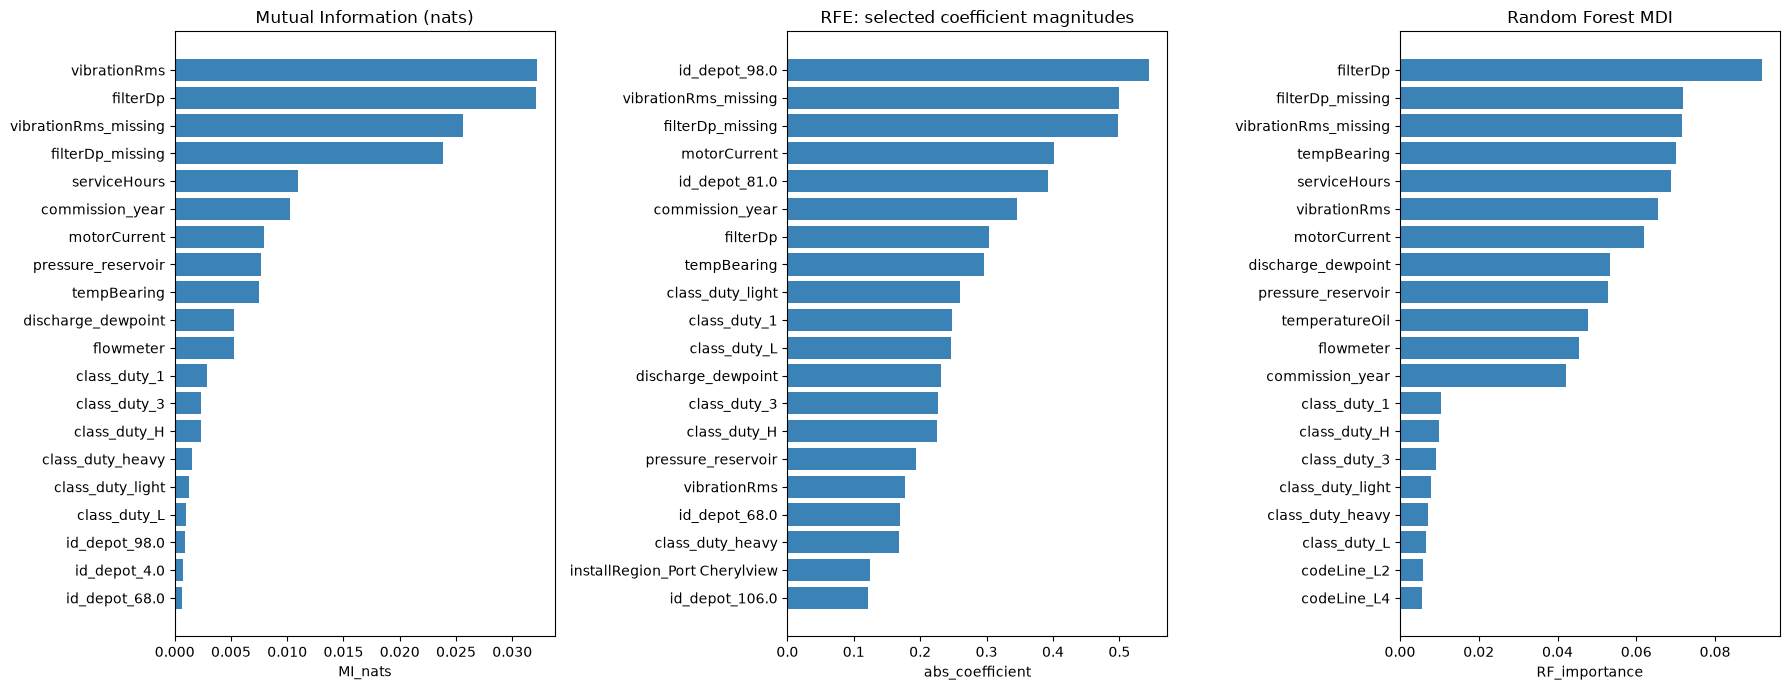

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, table, score, title in [
    (axes[0], mi_table.head(TOP_K), "MI_nats", "Mutual Information (nats)"),
    (axes[1], rfe_selected_table.head(TOP_K), "abs_coefficient", "RFE: selected coefficient magnitudes"),
    (axes[2], rf_table.head(TOP_K), "RF_importance", "Random Forest MDI"),
]:
    view = table.iloc[::-1]
    ax.barh(view.feature, view[score], color="#3B82B6")
    ax.set_title(title)
    ax.set_xlabel(score)
fig.tight_layout()
plt.show()

## 6. Comparison of methods

Compare the top 20 MI/forest features with RFE's 20 selections. Votes count top-list
appearances, not significance. For consensus, average feature ranks with equal
method weights and average ranks for ties. Do not average incompatible raw scores.
Lower consensus rank is better, but agreement does not prove predictive value.


In [9]:
top_mi = mi_table.loc[mi_table.MI_nats > 0].head(TOP_K).feature.to_list()
top_rfe = rfe_selected_table.feature.to_list()
top_rf = rf_table.loc[rf_table.RF_importance > 0].head(TOP_K).feature.to_list()
display(pd.DataFrame({"MI_top20": pd.Series(top_mi), "RFE_selected20": pd.Series(top_rfe),
                      "RF_top20": pd.Series(top_rf)}).rename_axis("display_position").rename(index=lambda i: i+1))

,MI_top20,RFE_selected20,RF_top20
display_position,,,
1,vibrationRms,id_depot_98.0,filterDp
2,filterDp,vibrationRms_missing,filterDp_missing
3,vibrationRms_missing,filterDp_missing,vibrationRms_missing
4,filterDp_missing,motorCurrent,tempBearing
5,serviceHours,id_depot_81.0,serviceHours
6,commission_year,commission_year,vibrationRms
7,motorCurrent,filterDp,motorCurrent
8,pressure_reservoir,tempBearing,discharge_dewpoint
9,tempBearing,class_duty_light,pressure_reservoir


In [10]:
ranking = (mi_table.set_index("feature").join(rfe_table.set_index("feature"))
           .join(rf_table.set_index("feature")))
ranking["RFE_comparison_rank"] = ranking.RFE_rank.rank(ascending=True, method="average")
ranking["mean_rank"] = ranking[["MI_rank", "RFE_comparison_rank", "RF_rank"]].mean(axis=1)
ranking["consensus_rank"] = ranking.mean_rank.rank(method="min")
ranking["MI_top20"] = ranking.index.isin(top_mi)
ranking["RFE_top20"] = ranking.index.isin(top_rfe)
ranking["RF_top20"] = ranking.index.isin(top_rf)
ranking["top20_votes"] = ranking[["MI_top20", "RFE_top20", "RF_top20"]].sum(axis=1)
ranking["original_group"] = feature_groups
ranking = ranking.sort_values(["mean_rank", "feature"])
assert not ranking.isna().any().any()
assert set(ranking.index) == set(X_candidates.columns)
print("Consensus ranking (full ranking is saved in Section 7):")
display(ranking.head(TOP_K).round(4))
print("Features receiving at least two top-20 votes:")
display(ranking.loc[ranking.top20_votes.ge(2),
    ["original_group", "MI_rank", "RFE_rank", "RF_rank", "top20_votes", "mean_rank"]].round(2))

sets = {"MI": set(top_mi), "RFE": set(top_rfe), "RF": set(top_rf)}
agreement = pd.DataFrame([[len(a & b) for b in sets.values()] for a in sets.values()],
    index=sets.keys(), columns=sets.keys())
print("Pairwise top-list overlap (counts):")
display(agreement)
print("In all three lists:", sorted(set.intersection(*sets.values())))

Consensus ranking (full ranking is saved in Section 7):


,MI_nats,MI_rank,RFE_rank,RFE_selected,RF_importance,RF_rank,RFE_comparison_rank,mean_rank,consensus_rank,MI_top20,RFE_top20,RF_top20,top20_votes,original_group
feature,,,,,,,,,,,,,,
filterDp,0.0321,2.0,1,True,0.0919,1.0,10.5,4.5000,1.0,True,True,True,3,filterDp
filterDp_missing,0.0238,4.0,1,True,0.0718,2.0,10.5,5.5000,2.0,True,True,True,3,filterDp
vibrationRms_missing,0.0256,3.0,1,True,0.0717,3.0,10.5,5.5000,2.0,True,True,True,3,vibrationRms
vibrationRms,0.0322,1.0,1,True,0.0656,6.0,10.5,5.8333,4.0,True,True,True,3,vibrationRms
tempBearing,0.0074,9.0,1,True,0.0701,4.0,10.5,7.8333,5.0,True,True,True,3,tempBearing
motorCurrent,0.0079,7.0,1,True,0.0620,7.0,10.5,8.1667,6.0,True,True,True,3,motorCurrent
pressure_reservoir,0.0077,8.0,1,True,0.0529,9.0,10.5,9.1667,7.0,True,True,True,3,pressure_reservoir
commission_year,0.0103,6.0,1,True,0.0421,12.0,10.5,9.5000,8.0,True,True,True,3,commission_year
discharge_dewpoint,0.0052,10.0,1,True,0.0533,8.0,10.5,9.5000,8.0,True,True,True,3,discharge_dewpoint


Features receiving at least two top-20 votes:


,original_group,MI_rank,RFE_rank,RF_rank,top20_votes,mean_rank
feature,,,,,,
filterDp,filterDp,2.0,1,1.0,3,4.50
filterDp_missing,filterDp,4.0,1,2.0,3,5.50
vibrationRms_missing,vibrationRms,3.0,1,3.0,3,5.50
vibrationRms,vibrationRms,1.0,1,6.0,3,5.83
tempBearing,tempBearing,9.0,1,4.0,3,7.83
motorCurrent,motorCurrent,7.0,1,7.0,3,8.17
pressure_reservoir,pressure_reservoir,8.0,1,9.0,3,9.17
commission_year,commission_year,6.0,1,12.0,3,9.50
discharge_dewpoint,discharge_dewpoint,10.0,1,8.0,3,9.50


Pairwise top-list overlap (counts):


,MI,RFE,RF
MI,20,17,17
RFE,17,20,15
RF,17,15,20


In all three lists: ['class_duty_1', 'class_duty_3', 'class_duty_H', 'class_duty_L', 'class_duty_heavy', 'class_duty_light', 'commission_year', 'discharge_dewpoint', 'filterDp', 'filterDp_missing', 'motorCurrent', 'pressure_reservoir', 'tempBearing', 'vibrationRms', 'vibrationRms_missing']


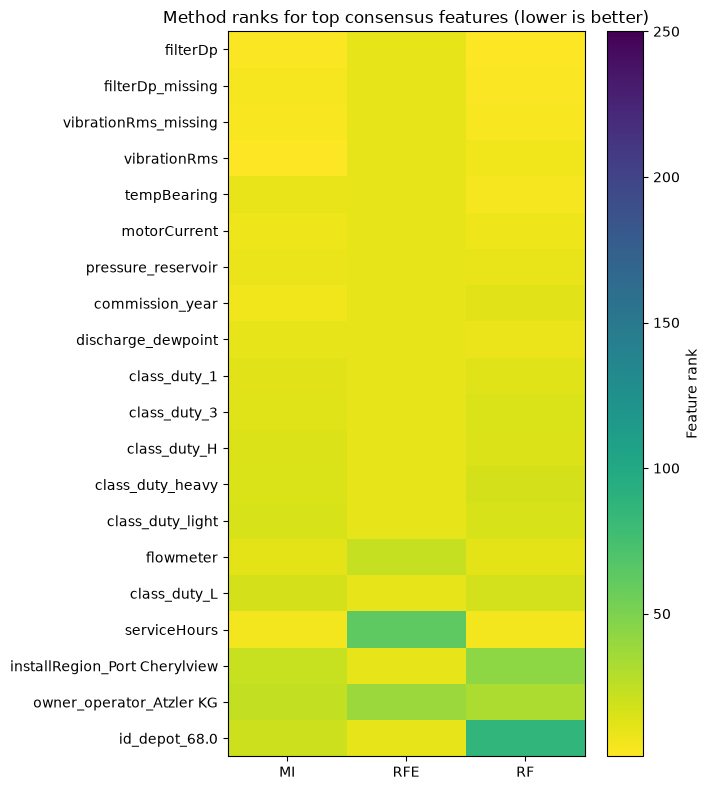

In [11]:
heat = ranking.head(TOP_K)[["MI_rank", "RFE_comparison_rank", "RF_rank"]]
fig, ax = plt.subplots(figsize=(7, 8))
plot = ax.imshow(heat, aspect="auto", vmin=1, vmax=len(ranking), cmap="viridis_r")
ax.set_xticks([0, 1, 2], labels=["MI", "RFE", "RF"])
ax.set_yticks(range(len(heat)), labels=heat.index)
ax.set_title("Method ranks for top consensus features (lower is better)")
fig.colorbar(plot, ax=ax, label="Feature rank")
fig.tight_layout()
plt.show()

### Original feature groups

Interpret sensor measurements together with their missingness flags, and categories
together with all their one-hot columns. A group gets a method vote if any child
is in that method's top list. Average the best child rank from each method to
summarise group evidence. This favours groups with more chances, so also report
column counts and avoid calling it an unbiased joint importance estimate.
RF group importance sums MDI; MI group maximum is **not** joint mutual information.
Category group scores and votes are exploratory, not evidence that each dummy is
independently useful. Duplicated metadata-missing dummies are represented separately
by the canonical metadata-availability flag.


This voting rule favours high-cardinality attributes: more dummy columns mean
more opportunities for at least one to enter each top-20 list. Two method votes
can therefore admit all 120 depot columns even if only a few rank highly.
Group voting is not adjusted for the number of categories.


In [12]:
group_ranking = ranking.groupby("original_group").agg(
    candidate_columns=("mean_rank", "size"), MI_max_nats=("MI_nats", "max"),
    RF_group_MDI=("RF_importance", "sum"), RFE_selected_columns=("RFE_selected", "sum"),
    MI_vote=("MI_top20", "max"), RFE_vote=("RFE_top20", "max"), RF_vote=("RF_top20", "max"),
    best_MI_rank=("MI_rank", "min"), best_RFE_rank=("RFE_comparison_rank", "min"),
    best_RF_rank=("RF_rank", "min"),
)
group_ranking["method_votes"] = group_ranking[["MI_vote", "RFE_vote", "RF_vote"]].sum(axis=1)
group_ranking["mean_best_child_rank"] = group_ranking[["best_MI_rank", "best_RFE_rank", "best_RF_rank"]].mean(axis=1)
group_ranking = group_ranking.sort_values(["method_votes", "mean_best_child_rank"], ascending=[False, True])
display(group_ranking.round(4))
display(Markdown("**Comparison:** MI/RFE overlap = " + str(agreement.loc["MI", "RFE"]) +
    ", MI/RF = " + str(agreement.loc["MI", "RF"]) + ", RFE/RF = " + str(agreement.loc["RFE", "RF"]) +
    ". Groups supported by at least two methods: " +
    ", ".join(group_ranking.index[group_ranking.method_votes.ge(2)]) +
    ". Different ranks are expected: MI is univariate, RFE is linear and conditional, "
    "and forests can use nonlinear splits and interactions. Redundancy can change which representative is favoured."))


,candidate_columns,MI_max_nats,RF_group_MDI,RFE_selected_columns,MI_vote,RFE_vote,RF_vote,best_MI_rank,best_RFE_rank,best_RF_rank,method_votes,mean_best_child_rank
original_group,,,,,,,,,,,,
filterDp,2,0.0321,0.1637,2,True,True,True,2.0,10.5,1.0,3,4.5000
vibrationRms,2,0.0322,0.1373,2,True,True,True,1.0,10.5,3.0,3,4.8333
tempBearing,1,0.0074,0.0701,1,True,True,True,9.0,10.5,4.0,3,7.8333
motorCurrent,1,0.0079,0.0620,1,True,True,True,7.0,10.5,7.0,3,8.1667
pressure_reservoir,1,0.0077,0.0529,1,True,True,True,8.0,10.5,9.0,3,9.1667
commission_year,1,0.0103,0.0421,1,True,True,True,6.0,10.5,12.0,3,9.5000
discharge_dewpoint,1,0.0052,0.0533,1,True,True,True,10.0,10.5,8.0,3,9.5000
class_duty,10,0.0029,0.0677,6,True,True,True,12.0,10.5,13.0,3,11.8333
flowmeter,1,0.0052,0.0455,0,True,False,True,11.0,23.0,11.0,2,15.0000


**Comparison:** MI/RFE overlap = 17, MI/RF = 17, RFE/RF = 15. Groups supported by at least two methods: filterDp, vibrationRms, tempBearing, motorCurrent, pressure_reservoir, commission_year, discharge_dewpoint, class_duty, flowmeter, id_depot, serviceHours. Different ranks are expected: MI is univariate, RFE is linear and conditional, and forests can use nonlinear splits and interactions. Redundancy can change which representative is favoured.

## 7. Final ranking and selected features

Keep two candidates using the same rankings:

- **With depot:** preserve the original 142 columns from 11 groups, including
  all 120 id_depot columns admitted by the group-voting rule.
- **Without depot:** remove only the entire id_depot group. Keep all columns
  from the other selected groups: 22 columns from 10 groups.

Depot may contain useful operational information. However, 120 dummies add model
complexity and opportunities to fit depot-specific patterns in repeated readings.
These patterns may not transfer to new locations. Depot is a location identifier,
not the unit ID; removing it reduces direct location dependence but cannot remove
all device/location proxies or guarantee freedom from overfitting.

The table compares these trade-offs, not measured performance. Neither candidate
is optimal or proven better. Rankings remain computed on the original candidates;
we do not rerank them on the compact subset. Both retain every training observation.

Save both lists, group names and duplicate aliases in a short JSON file under
`feature_subsets`. For compatibility,
top-level `selected_features`, `selected_original_groups` and the ranking CSV's
existing selection marker still refer to the original with-depot candidate.
Later comparisons must use verified device groups, with preprocessing and feature
selection fitted inside training folds. Keep the held-out test set untouched.


In [13]:
selected_groups = group_ranking.index[group_ranking.method_votes.ge(2)].to_list()
selected_features = [c for c in X_candidates if feature_groups[c] in selected_groups]
X_selected = X[selected_features].copy()
assert X_selected.index.equals(y.index) and len(X_selected) == 10512
assert np.isfinite(X_selected.to_numpy()).all()
ranking["proposed_selected"] = ranking.index.isin(selected_features)
print(f"Proposed subset: {len(selected_features)} encoded features from {len(selected_groups)} groups.")
display(group_ranking.loc[selected_groups, ["candidate_columns", "method_votes", "mean_best_child_rank"]].round(2))
display(pd.Series(selected_features, name="selected_feature").to_frame())

# Keep the original candidate and remove only depot from the second candidate.
depot_features = [c for c in selected_features if feature_groups[c] == "id_depot"]
compact_groups = [g for g in selected_groups if g != "id_depot"]
compact_features = [c for c in selected_features if feature_groups[c] != "id_depot"]
assert depot_features and compact_features
assert set(selected_features) - set(compact_features) == set(depot_features)
X_compact = X[compact_features].copy()
assert X_compact.index.equals(y.index) and len(X_compact) == len(X_selected)
assert np.isfinite(X_compact.to_numpy()).all()

Proposed subset: 142 encoded features from 11 groups.


,candidate_columns,method_votes,mean_best_child_rank
original_group,,,
filterDp,2,3,4.50
vibrationRms,2,3,4.83
tempBearing,1,3,7.83
motorCurrent,1,3,8.17
pressure_reservoir,1,3,9.17
commission_year,1,3,9.50
discharge_dewpoint,1,3,9.50
class_duty,10,3,11.83
flowmeter,1,2,15.00


,selected_feature
0,motorCurrent
1,filterDp
2,pressure_reservoir
3,vibrationRms
4,flowmeter
...,...
137,id_depot_98.0
138,id_depot_99.0
139,filterDp_missing
140,vibrationRms_missing


In [14]:
subset_comparison = pd.DataFrame([
    {"candidate": "with_depot", "columns": len(selected_features),
     "group_count": len(selected_groups), "original_groups": ", ".join(selected_groups),
     "advantages": "Preserves all groups supported by voting, including possible depot information.",
     "limitations": "120 depot dummies add complexity and risk fitting location-specific patterns."},
    {"candidate": "without_depot", "columns": len(compact_features),
     "group_count": len(compact_groups), "original_groups": ", ".join(compact_groups),
     "advantages": "Simpler; no direct depot encoding; all other selected groups preserved.",
     "limitations": "May lose useful depot information; other location proxies and timing risks remain."},
]).set_index("candidate")
print("Two exploratory candidates; rankings are unchanged:")
with pd.option_context("display.max_colwidth", None):
    display(subset_comparison)

Two exploratory candidates; rankings are unchanged:


,columns,group_count,original_groups,advantages,limitations
candidate,,,,,
with_depot,142,11,"filterDp, vibrationRms, tempBearing, motorCurrent, pressure_reservoir, commission_year, discharge_dewpoint, class_duty, flowmeter, id_depot, serviceHours","Preserves all groups supported by voting, including possible depot information.",120 depot dummies add complexity and risk fitting location-specific patterns.
without_depot,22,10,"filterDp, vibrationRms, tempBearing, motorCurrent, pressure_reservoir, commission_year, discharge_dewpoint, class_duty, flowmeter, serviceHours",Simpler; no direct depot encoding; all other selected groups preserved.,May lose useful depot information; other location proxies and timing risks remain.


In [15]:
OUTPUT_DIR = TRAIN_CSV.parent
RANKING_CSV = OUTPUT_DIR / "phase2_2_feature_ranking.csv"
GROUP_CSV = OUTPUT_DIR / "phase2_2_group_ranking.csv"
SELECTION_JSON = OUTPUT_DIR / "phase2_2_selected_features.json"
ranking.to_csv(RANKING_CSV, index_label="feature")
group_ranking.to_csv(GROUP_CSV, index_label="original_group")
# Keep the old top-level list for compatibility; both named candidates are explicit.
feature_subsets = {
    "with_depot": {"selected_features": selected_features,
                   "selected_original_groups": selected_groups},
    "without_depot": {"selected_features": compact_features,
                      "selected_original_groups": compact_groups},
}
for subset in feature_subsets.values():
    names = subset["selected_features"]
    assert len(names) == len(set(names)) and set(names) <= set(X.columns)
    assert "Failure" not in names
    subset["column_count"] = len(names)
    subset["group_count"] = len(subset["selected_original_groups"])

specification = {
    "source_csv": TRAIN_CSV.name, "preprocessing_variant": "Standard",
    "training_rows": len(X), "input_predictors": X.shape[1],
    "candidate_predictors": X_candidates.shape[1], "seed": SEED,
    "top_k_per_method": TOP_K, "legacy_subset_name": "with_depot",
    "selected_features": selected_features, "selected_original_groups": selected_groups,
    "duplicate_aliases": aliases, "constant_columns": constant_features,
    "feature_subsets": feature_subsets,
}
SELECTION_JSON.write_text(json.dumps(specification, indent=2) + "\n", encoding="utf-8")
saved_spec = json.loads(SELECTION_JSON.read_text(encoding="utf-8"))
assert saved_spec["feature_subsets"] == feature_subsets
for output in [RANKING_CSV, GROUP_CSV, SELECTION_JSON]:
    print(output, f"({output.stat().st_size:,} bytes)")

..\data\processed\phase2_2_feature_ranking.csv (36,850 bytes)
..\data\processed\phase2_2_group_ranking.csv (1,893 bytes)
..\data\processed\phase2_2_selected_features.json (9,302 bytes)


## 8. Conclusions and decisions for Phase 2.3

The three methods share **15 top-list features**, including filterDp,
vibrationRms, their missingness flags, tempBearing and motorCurrent. MI/RFE and
MI/forest each overlap on 17 features; RFE/forest overlap on 15. Service hours
rank highly for MI and the forest but are excluded by the 20-column RFE fit.

Two candidates are saved: **with_depot** keeps the original **142 columns from
11 groups**; **without_depot** keeps **22 columns from 10 groups**. The only
change is excluding all 120 depot columns. The compact candidate preserves the
nine selected numeric attribute groups and class_duty, including retained flags.

Group voting gives high-cardinality attributes more chances to enter the shortlist.
The broad candidate retains potential depot information but may fit site-specific
patterns. The compact candidate reduces complexity but may discard real signal.
Neither has demonstrated a predictive advantage; compare both later using proper
grouped validation and fold-fitted preprocessing and selection.
Owner/operator and installation region were evaluated but did not meet the
cross-method group rule, which does not prove that they are irrelevant.

These results cover 2.2(A), (B) and (C). Both subsets are starting points,
not optimal or validated feature sets.

Missing filterDp/vibrationRms and other availability signals can reflect reporting
or failure-recording procedures. Do not infer that they were known before Failure.
The perfect-proxy check is only a basic audit; it cannot rule out timing leakage.
Metadata timing, including serviceHours, remains unverified. Class-balanced RFE
and forest fits help address imbalance but do not remove these limitations.

Repeated measurements give more influence to frequently observed devices, and
static metadata can be memorised. Group mappings are unavailable in this export;
no predictive performance has been estimated. Phase 2.3 must retain verified
device IDs and fit preprocessing and feature selection inside grouped training
folds. Keep the existing test set untouched until final evaluation. Consider
feature-group stability and alternatives without missingness/metadata if their
prediction-time availability cannot be confirmed. No Phase 2.3 pipeline or final
ML solution is implemented here.
